# Prolog

In [1]:
import pandas as pd
import seaborn as sb
import os
import OHCParser as op
import datetime
import traceback
from scipy.optimize import curve_fit
from matplotlib.ticker import FormatStrFormatter
import matplotlib
from matplotlib import pyplot as plt
import numpy as np
import pathlib

## Auxiliary methods


In [2]:
#
CPUGen_sorting_order = [
    'Rome (2nd-gen)','Milan (3rd-gen)','Genoa (4th-gen)','Turin (5th-gen)',
    'ARMv8.2','ARMv9','ARMv9.2','Skylake (1st-gen)','Broadwell','Cascade Lake (2nd-gen)',
    'Sapphire Rapids (4th-gen)','Emerald Rapids (5th-gen)',
    'i9']

In [3]:
# Secondary x-axis for cells per core
def addSecondaryAxisCellsPerCore(ax, cellsNumber, labelFontSize = 7):
    ticksCellsPerCoreInT = [round(cellsNumber/n/1000, 1) for n in ax.get_xticks()]
    tickLabelsStr = [f'{val:.0f}' if val%1 < 1e-1 else f'{val:.1f}' \
            for val in ticksCellsPerCoreInT]
    ax2 = ax.twiny()

    ax2.set_xscale("log")
    ax2.set_xticks(ax.get_xticks())
    ax2.set_xticklabels(tickLabelsStr, fontsize=labelFontSize)
    ax2.set_xlim(ax.get_xlim())
    ax2.set_xlabel("Number of Cells per Core in thousands")
    ax2.tick_params(axis='x', which='both', labelrotation=90)

    formatter = matplotlib.ticker.LogFormatter(labelOnlyBase=False, minor_thresholds=(3, 1))
    ax2.xaxis.set_minor_formatter(formatter)
    ticksCellsPerCoreInT = [round(cellsNumber/n/1000, 1) for n in ax.get_xticks(minor=True)]
    tickLabelsStr = [f'{val:.0f}' if val%1 < 1e-1 else f'{val:.1f}' \
             for val in ticksCellsPerCoreInT]
    ax2.set_xticks(ax.get_xticks(minor=True), minor=True)
    ax2.set_xlim(ax.get_xlim())
    ax2.set_xticklabels(tickLabelsStr, minor=True, fontsize=labelFontSize)
    return ax2


# Overlay Time-vs-Energy Pareto fronts for cumulative CPU-release-year cutoffs,
# as in the faceted "CPU Model" plot. Relies on release_map_orig / _norm_gen /
# paretoset defined in the "CPU Model" cell (resolved at call time).
def addParetoFronts(ax, df, years=(2020, 2022, 2024)):
    dash_map = {
        2020: [(5, 3)],
        2022: [(2, 2)],
        2024: [(5, 1)],
    }
    df = df.copy()
    df["year"] = df["CPU Generation"].apply(lambda x: release_map_orig[_norm_gen(x)])
    for year in years:
        df_year = df[df["year"] <= year].copy()
        df_year["Cutoff"] = year
        mask = paretoset(
            df_year[["Time-To-Solution [h]", "Energy-To-Solution [kWh]"]],
            sense=[min, min],
        )
        sb.lineplot(
            df_year[mask], x="Energy-To-Solution [kWh]",
            y="Time-To-Solution [h]", ax=ax, color="black",
            style="Cutoff", dashes=dash_map[year],
        )

## Load submissions

In [4]:
# general data
size_coarse=65e6
size_medium=110e6
size_fine=236e6

# The submissions folder holds the OHC2 spreadsheets only; the OHC1 entries are
# taken from the exported data set of the previous edition.
dfs = op.read_submissions_all_editions()
dfs["Mesh"] = pd.Categorical(dfs["Mesh"], ["coarse", "medium", "fine"], ordered=True)

# provide filtered data
df_hardware = dfs[dfs["Track"] == "Hardware Track"]
df_hardware = df_hardware.sort_values("CPU Family")
df_software = dfs[dfs["Track"] == "Software Track"]
df_hw_coarse = df_hardware[df_hardware["Mesh"]=="coarse"]
df_hw_medium = df_hardware[df_hardware["Mesh"]=="medium"]
df_hw_fine = df_hardware[df_hardware["Mesh"]=="fine"]

fig_folder = "figures_hwtrack"
doSaveFig = True

last time the data was updated 2026-11-01 18:11:14.149126  by  mawasserman


01_Wikki_DrivAer_hardware_236M Sergey Lesnik (Wikki).xlsm: 3 of 11 runs without energy data


01_Wikki_DrivAer_hardware_65M Sergey Lesnik (Wikki).xlsm: 4 of 11 runs without energy data


NOTE: 'Energy per Iteration [J]', 'Energy per Iteration [kJ]' and 'Energy-To-Solution [kWh]' are TDP-based for all entries.


# Submission overview

saving figure to figures_hwtrack/submissions_overview_TTS.png


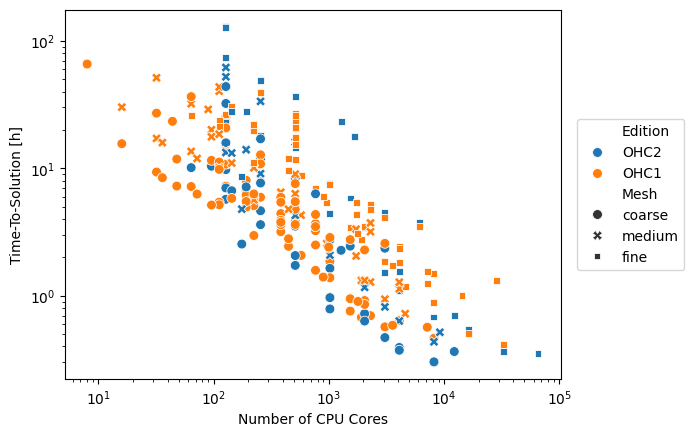

In [5]:
fig, ax = plt.subplots()
sb.scatterplot(df_hardware,x="Number of CPU Cores", y="Time-To-Solution [h]", style="Mesh", s=50, hue="Edition", ax=ax)
ax.set(xscale="log", yscale="log") #, title=" Hardware Track")
ax.set(ylabel="Time-To-Solution [h]")
#sb.move_legend(ax, loc=bbox_to_anchor=(1, 1))
sb.move_legend(ax, "center left", bbox_to_anchor=(1.02, 0.5))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "submissions_overview_TTS", doSaveFig)

saving figure to figures_hwtrack/submissions_overview_ETS.png


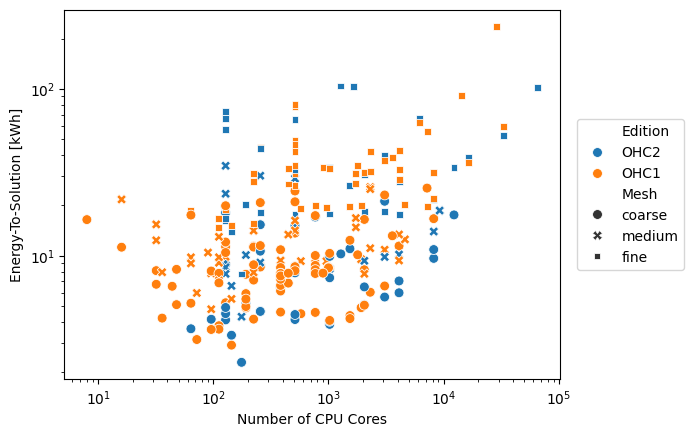

In [6]:
fig, ax = plt.subplots()
sb.scatterplot(df_hardware,x="Number of CPU Cores", y="Energy-To-Solution [kWh]", style="Mesh", s=50, hue="Edition", ax=ax)
ax.set(xscale="log", yscale="log") #, title=" Hardware Track")
ax.set(ylabel="Energy-To-Solution [kWh]")
#sb.move_legend(ax, loc=bbox_to_anchor=(1, 1))
sb.move_legend(ax, "center left", bbox_to_anchor=(1.02, 0.5))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "submissions_overview_ETS", doSaveFig)

saving figure to figures_hwtrack/submissions_overview_cpu.png


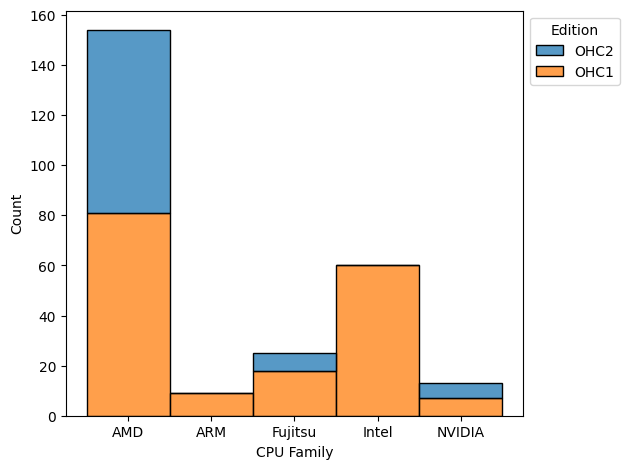

In [7]:
fig, ax = plt.subplots()
sb.histplot(df_hardware, x="CPU Family",
            hue="Edition",
            ax=ax,
            multiple="stack",
            stat="count",
            ec="k"
           )
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
op.save_fig(ax.get_figure(), fig_folder, "submissions_overview_cpu", doSaveFig)

## OHC2 submissions breakdown

saving figure to figures_hwtrack/submissions_overview_cpu_OHC2.png


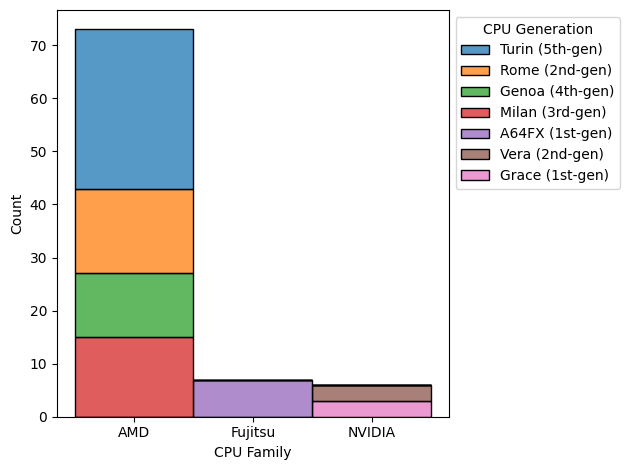

In [8]:
df = df_hardware[df_hardware["Edition"] == "OHC2"]
fig, ax = plt.subplots()
sb.histplot(df, x="CPU Family",
            hue="CPU Generation",
            ax=ax,
            multiple="stack",
            stat="count",
            ec="k"
           )
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
op.save_fig(ax.get_figure(), fig_folder, "submissions_overview_cpu_OHC2", doSaveFig)

<Axes: xlabel='Mesh', ylabel='percent'>

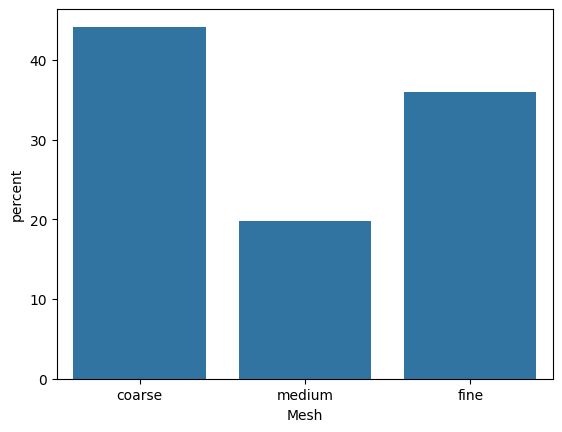

In [9]:
df = df_hardware[df_hardware["Edition"] == "OHC2"]
fig, ax = plt.subplots()
sb.countplot(df, x="Mesh", stat="percent", ax=ax)

## Submission counts

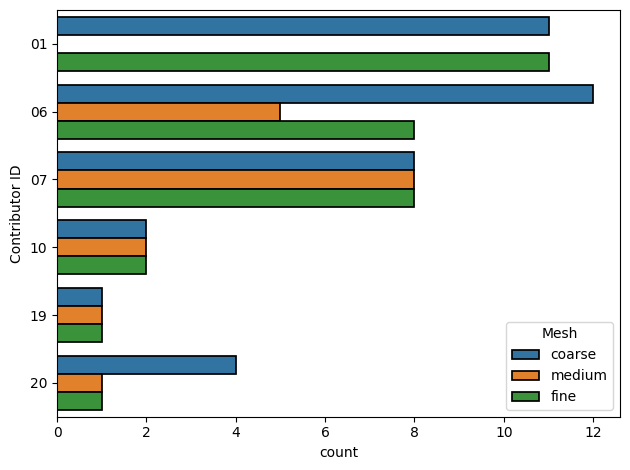

In [10]:
df = df_hardware[df_hardware["Edition"] == "OHC2"]
df = df.sort_values(by=["Contributor ID", "Mesh"])
fig, ax = plt.subplots()
sb.countplot(df, hue="Mesh",
            y="Contributor ID",
            ax=ax,
            stat="count",
            edgecolor='black',
            linewidth=1.25,
           )
labels = [str(v) if v else '' for v in ax.containers[0].datavalues]
plt.tight_layout()

## Energy model validation

saving figure to figures_hwtrack/ReportedEnergy_over_TDPEnergy-cores.png


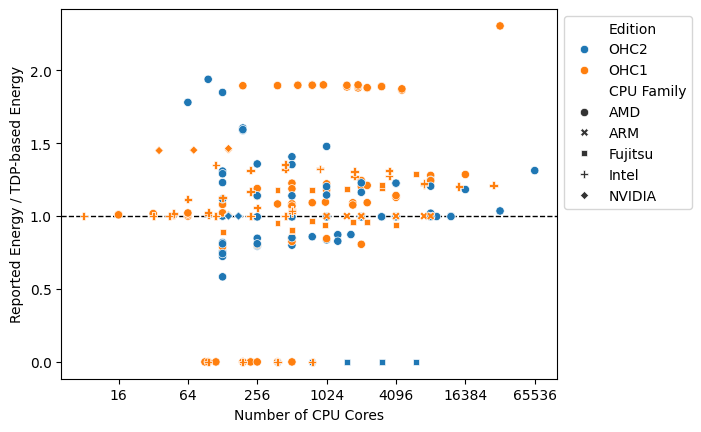

In [11]:
# Sanity check of the TDP-based energy model against the energy values that
# contributors actually reported. A ratio close to 1 means the TDP estimate
# matches the measurement; values >1 mean the run drew more than its TDP would
# suggest. Submissions without a reported measurement are kept and shown at a
# ratio of 0 (they carry a placeholder consumed energy).
df = df_hardware.copy()
df["Reported / TDP Energy"] = \
    df["Run Consumed Energy [kWh]"] / df["Energy-To-Solution [kWh]"]
df.loc[df["Is Energy Reported"] == 0, "Reported / TDP Energy"] = 0.0
df.sort_values("CPU Family", inplace=True)

fig, ax = plt.subplots()
sb.scatterplot(
    df, x="Number of CPU Cores", y="Reported / TDP Energy", hue="Edition", style="CPU Family", ax=ax
)
ax.axhline(1.0, color="black", linestyle="--", linewidth=1, zorder=0)
ax.set_xscale("log", base=2)
# Integer core counts on the x-axis (avoid scientific notation for large values)
ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))
ax.set_ylabel("Reported Energy / TDP-based Energy")
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "ReportedEnergy_over_TDPEnergy-cores", doSaveFig)

# Time vs Energy trade-off

## Pareto fronts by CPU release year

saving figure to figures_hwtrack/TTS_ETS_facetGrid_pareto_year.png


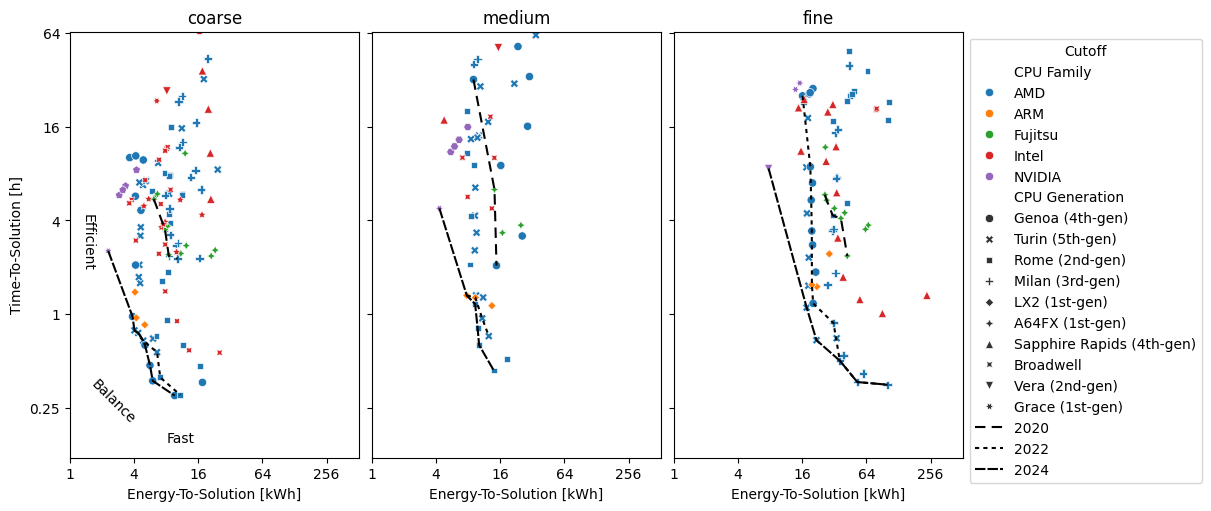

In [12]:
from paretoset import paretoset


# The legend has ~20 entries (CPU Family + CPU Generation + Cutoff). With
# layout="constrained" the axes are shrunk to make room for it, so the figure
# needs enough height for the legend or the plots collapse into a thin strip.
fig, axs = plt.subplots(1, 3, figsize=(12, 5), layout="constrained", gridspec_kw={"hspace": 0.1}, sharey=True, sharex=True)

release_map_orig = {
    "i9": 2024, # Feb. 2024
    'Milan (3rd-gen)': 2021,
    "Genoa (4th-gen)": 2022,
    'Rome (2nd-gen)': 2019,
    'Sapphire Rapids (4th-gen)': 2023,
    "Cascade Lake (2nd-gen)": 2019,
    "Turin (5th-gen)": 2024,
    "Broadwell" : 2014,
    "Skylake (1st-gen)": 2015,
    "Emerald Rapids (5th-gen)": 2023,
    'A64FX (1st-gen)': 2016,
    'LX2 (1st-gen)': 2021,
    'Grace (1st-gen)': 2023,
    'MI300A (1st-gen)': 2023,
    'Vera (2nd-gen)': 2023}

df_hardware["year"] = 0
# Normalize keys and lookups so this cell works whether or not an earlier cell
# already stripped the "-gen" suffix from the CPU Generation labels.
def _norm_gen(g): return g.replace("-gen)", ")")
release_map_orig = {_norm_gen(k): v for k, v in release_map_orig.items()}
# release_map_2 = {_norm_gen(k): v for k, v in release_map_2.items()}
df_hardware["year"] = df_hardware["CPU Generation"].apply(lambda x: release_map_orig[_norm_gen(x)])
# df_hardware["Year (binned)"] = df_hardware["CPU Generation"].apply(lambda x: release_map_2[_norm_gen(x)])


for i, mesh in enumerate(["coarse", "medium", "fine"]):
    df_hardware_coarse = df_hardware[df_hardware["Mesh"] == mesh]
    ax = sb.scatterplot(df_hardware_coarse,x="Energy-To-Solution [kWh]", y="Time-To-Solution [h]", hue="CPU Family", style="CPU Generation", ax=axs[i])
    ax.set_title(mesh)

    for year in  [2020, 2022, 2024]: #["2014-2020", "2020-2024"]: # ["2014-2020", "2020-2022", "2022-2024"]:
        dash_map={
            2017: [(1, 5)],
            2020: [(5, 3)],
            2022: [(2, 2)],
            2024: [(5, 1)],
        }

        df_year = df_hardware_coarse[df_hardware_coarse["year"] <= year].copy()
        df_year["Cutoff"] = year
        mask = paretoset(df_year[["Time-To-Solution [h]", "Energy-To-Solution [kWh]"]], sense=[min, min])
        axII=sb.lineplot(
            df_year[mask], x="Energy-To-Solution [kWh]",
            y="Time-To-Solution [h]", ax=axs[i], color="black",
            style="Cutoff", dashes=dash_map[year]
        )
    if i != 2:
        ax.get_legend().set_visible(False)

for ax in axs.flat:
    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.4g'))
    ax.set_yscale("log", base=2)
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.4g'))
    ax.set_xlim([1, 512])
    ax.set_ylim([0.12, 65])

axs[0].text(8, 0.15, "Fast") #, ha="left", va="top", transform=ax.transAxes)
axs[0].text(1.25, 2.0, "Efficient", rotation=-90) #, ha="left", va="top", transform=ax.transAxes)
axs[0].text(1.5, 0.2, "Balance", rotation=-45) #, ha="left", va="top", transform=ax.transAxes)

fig = ax.get_figure()
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
op.save_fig(fig, fig_folder, "TTS_ETS_facetGrid_pareto_year", doSaveFig)

## Coarse mesh

saving figure to figures_hwtrack/CPU Model-singleNode-coarse.png


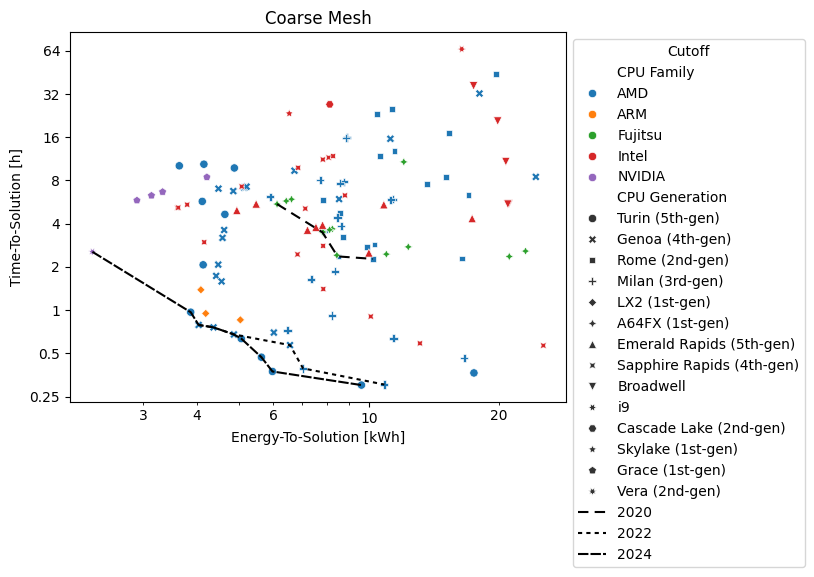

In [13]:
df = df_hw_coarse
# Sort the DataFrame by CPU Generation and Mesh to ensure the correct order in the plots
# df["CPUGenIndex"] = df["CPU Generation"].apply(lambda gen: CPUGen_sorting_order.index(gen))
# df["MeshIndex"] = df["Mesh"].apply(lambda mesh: ["coarse","medium","fine"].index(mesh))
# df = df.sort_values(["MeshIndex", "CPUGenIndex"])
fig, ax = plt.subplots()
sb.scatterplot(df.sort_values("CPU Family"),x="Energy-To-Solution [kWh]", y="Time-To-Solution [h]", hue="CPU Family", style="CPU Generation", ax=ax)
addParetoFronts(ax, df)
ax.set(xscale="log", title="Coarse Mesh")
ax.set_yscale("log", base=2)
ax.yaxis.set_major_formatter(FormatStrFormatter('%.2g'))
ax.xaxis.set_major_formatter(FormatStrFormatter('%.4g'))
formatter = matplotlib.ticker.LogFormatter(labelOnlyBase=False, minor_thresholds=(2, 1))
ax.xaxis.set_minor_formatter(formatter)
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "CPU Model-singleNode-coarse", doSaveFig)

## Medium mesh

saving figure to figures_hwtrack/CPU Model-singleNode-medium.png


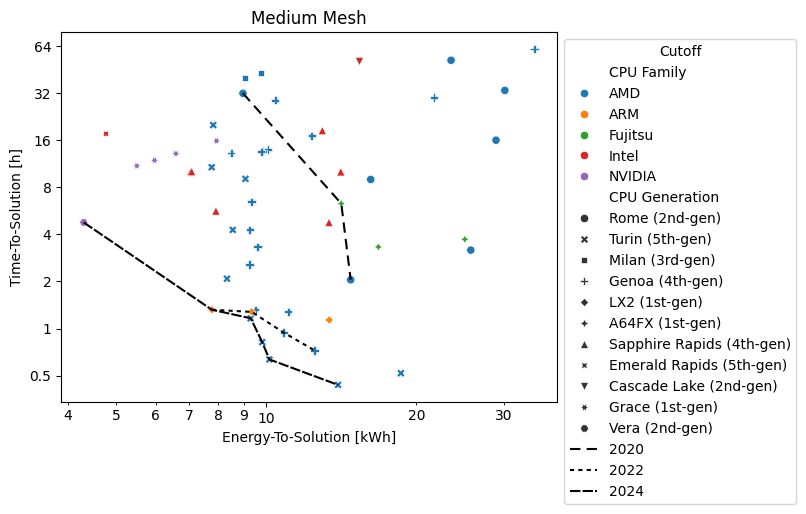

In [14]:
df = df_hw_medium
fig, ax = plt.subplots()
sb.scatterplot(df.sort_values("CPU Family"),x="Energy-To-Solution [kWh]", y="Time-To-Solution [h]", hue="CPU Family", style="CPU Generation", ax=ax)
addParetoFronts(ax, df)
ax.set(xscale="log", title="Medium Mesh")
ax.set_yscale("log", base=2)
ax.yaxis.set_major_formatter(FormatStrFormatter('%.2g'))
ax.xaxis.set_major_formatter(FormatStrFormatter('%.4g'))
formatter = matplotlib.ticker.LogFormatter(labelOnlyBase=False, minor_thresholds=(2, 1))
ax.xaxis.set_minor_formatter(formatter)
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "CPU Model-singleNode-medium", doSaveFig)

## Fine mesh

saving figure to figures_hwtrack/CPU Model-singleNode-fine.png


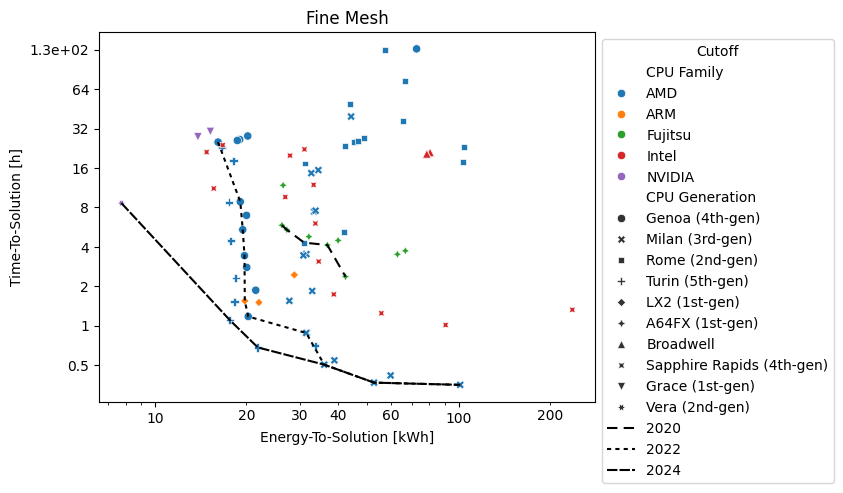

In [15]:
df = df_hw_fine
fig, ax = plt.subplots()
sb.scatterplot(df.sort_values("CPU Family"),x="Energy-To-Solution [kWh]", y="Time-To-Solution [h]", hue="CPU Family", style="CPU Generation", ax=ax)
addParetoFronts(ax, df)
ax.set(xscale="log", title="Fine Mesh")
ax.set_yscale("log", base=2)
ax.yaxis.set_major_formatter(FormatStrFormatter('%.2g'))
ax.xaxis.set_major_formatter(FormatStrFormatter('%.4g'))
formatter = matplotlib.ticker.LogFormatter(labelOnlyBase=False, minor_thresholds=(2, 1))
ax.xaxis.set_minor_formatter(formatter)
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "CPU Model-singleNode-fine", doSaveFig)

# Scaling

## Strong scaling

/var/folders/j_/dps_4h917q30x09r6yjydlb80000gn/T/ipykernel_61734/2554170827.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = df[df.groupby(["CPU Generation", "Mesh"])["CPU Generation"].transform(len) > 2]


/tmp/nbexec/lib/python3.12/site-packages/statsmodels/nonparametric/smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),


Mesh = coarse | CPU Family = AMD
Mesh = coarse | CPU Family = Fujitsu
Mesh = coarse | CPU Family = Intel
Mesh = fine | CPU Family = AMD
Mesh = fine | CPU Family = Fujitsu
Mesh = fine | CPU Family = Intel
saving figure to figures_hwtrack/strong_scaling_facetgrid.png


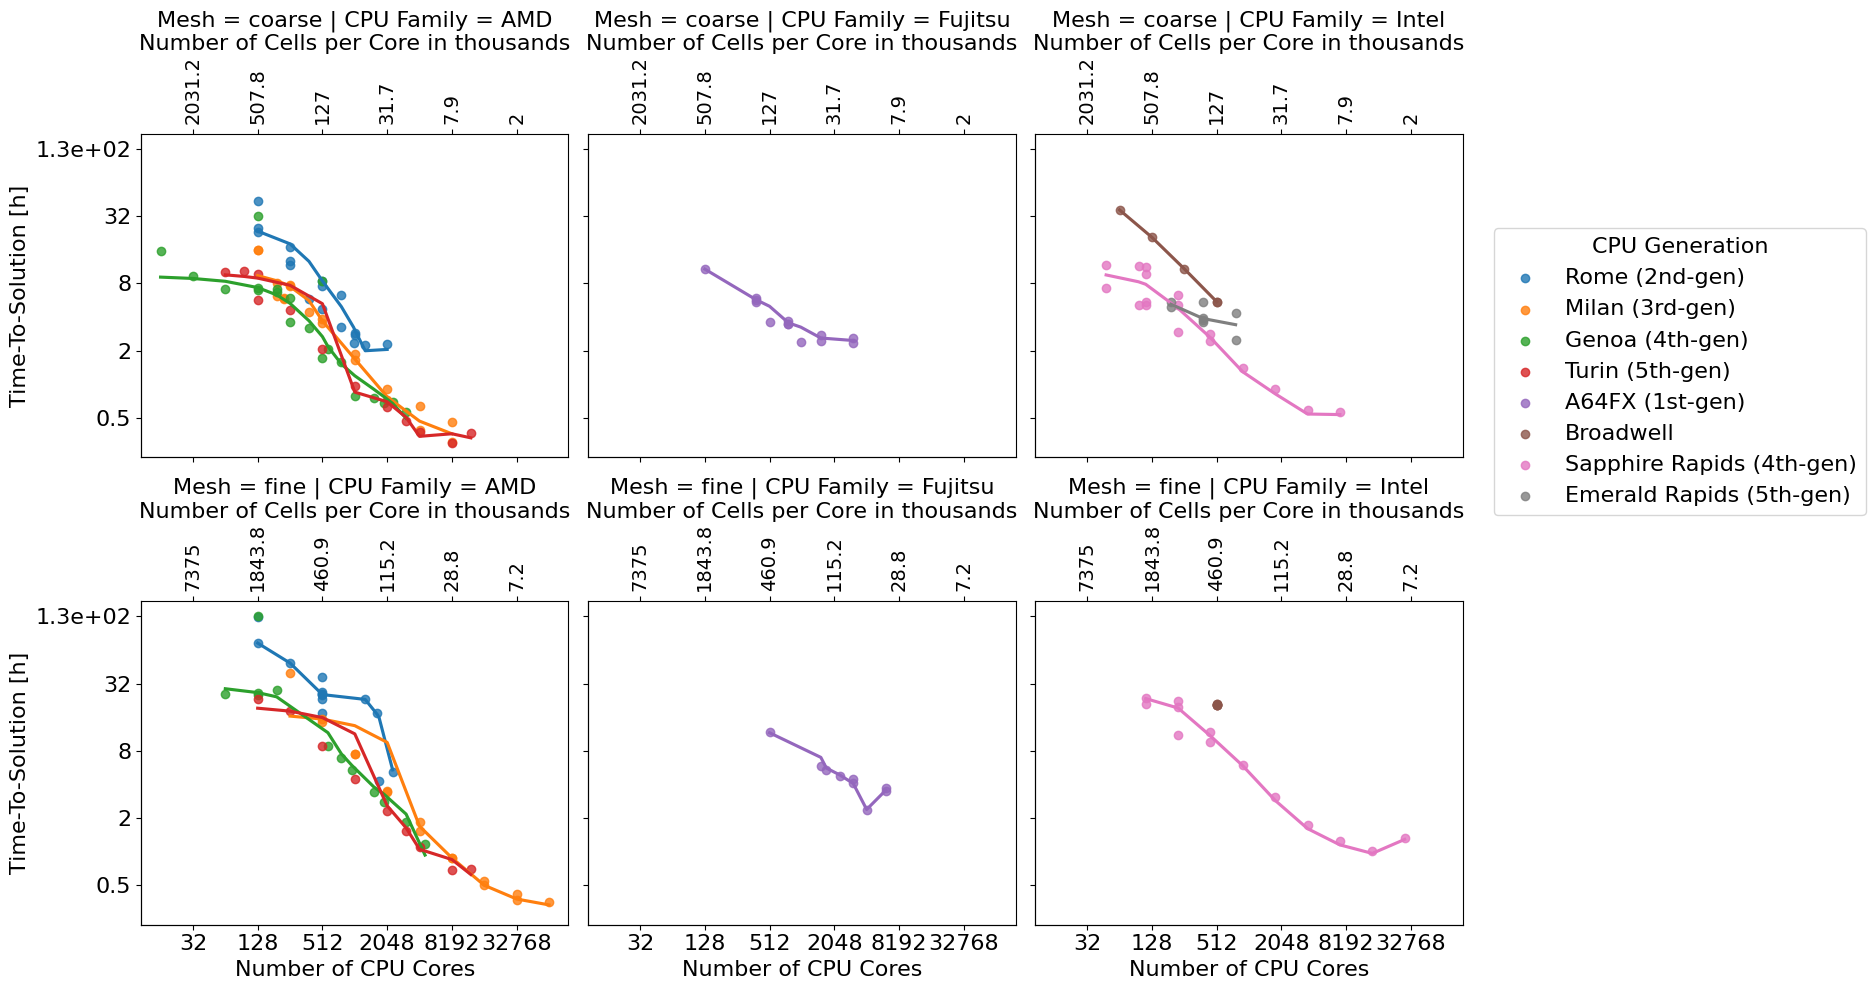

In [16]:
# Use only CPUs with more than one entry per CPU Generation and Mesh combination, to ensure that the lowess fit is meaningful
df = df_hardware
df = df[df.groupby(["CPU Generation", "Mesh"])["CPU Generation"].transform(len) > 2]
df = df[df["CPU Family"] != "ARM"]  # Exclude ARM CPUs for this analysis
df = df[df["CPU Family"] != "NVIDIA"]  # Exclude "Other" CPU Generations for this analysis
df = df[df["Mesh"] != "medium"]  # Exclude "Other" CPU Generations for this analysis

# Sort the DataFrame by CPU Generation and Mesh to ensure the correct order in the plots
CPUGen_sorting_order = [
    'Rome (2nd-gen)','Milan (3rd-gen)','Genoa (4th-gen)','Turin (5th-gen)',
    'ARMv8.2','ARMv9','A64FX (1st-gen)','Skylake (1st-gen)','Broadwell','Cascade Lake (2nd-gen)',
    'Sapphire Rapids (4th-gen)','Emerald Rapids (5th-gen)',
    'i9']
df["CPUGenIndex"] = df["CPU Generation"].apply(lambda gen: CPUGen_sorting_order.index(gen))
df["MeshIndex"] = df["Mesh"].apply(lambda mesh: ["coarse","medium","fine"].index(mesh))
df = df[df["Mesh"] != "medium"]
# Mesh is categorical; drop the filtered-out level or lmplot draws an empty facet row for it
df["Mesh"] = df["Mesh"].cat.remove_unused_categories()
df = df.sort_values(["MeshIndex", "CPUGenIndex"])

# df["MeshIndex"] = df["Mesh"].apply(lambda mesh: ["coarse","medium","fine"].index(mesh))
# df = df.sort_values(["MeshIndex"])

ax = sb.lmplot(
    df,
    x="Number of CPU Cores",
    y="Time-To-Solution [h]",
    hue="CPU Generation",
    ci=None,
    col="CPU Family",
    row="Mesh",
    lowess=True,
    )

# Adjust axes, labels, and legend
figFontSize = 16
for a in ax.axes.flat:
    print(a.get_title())
    a.set_xscale("log", base=2)
    a.set_yscale("log", base=2)
    a.xaxis.set_major_formatter(FormatStrFormatter('%.5g'))
    a.yaxis.set_major_formatter(FormatStrFormatter('%.2g'))
    title = a.get_title()
    if "coarse" in title:
        size = size_coarse
    elif "medium" in title:
        size = size_medium
    elif "fine" in title:
        size = size_fine
    else:
        raise ValueError(f"Unexpected title: {title}")
    ax2 = addSecondaryAxisCellsPerCore(a, size, labelFontSize=14)
    fig = a.get_figure()
    for item in ([a.title, a.xaxis.label, a.yaxis.label, ax2.xaxis.label] +
             a.get_xticklabels() + a.get_yticklabels() + ax._legend.texts):
        item.set_fontsize(figFontSize)

ax.tight_layout()
sb.move_legend(ax, "lower right", bbox_to_anchor=(1.08, 0.48), borderaxespad=0,
               frameon=True, ncol=1, fontsize=figFontSize, title_fontsize=figFontSize)
op.save_fig(fig, fig_folder, "strong_scaling_facetgrid", doSaveFig)

## Parallel efficiency

/tmp/nbexec/lib/python3.12/site-packages/statsmodels/nonparametric/smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),


saving figure to figures_hwtrack/efficiency_cores_facetGrid_mesh_CPUFamily.png


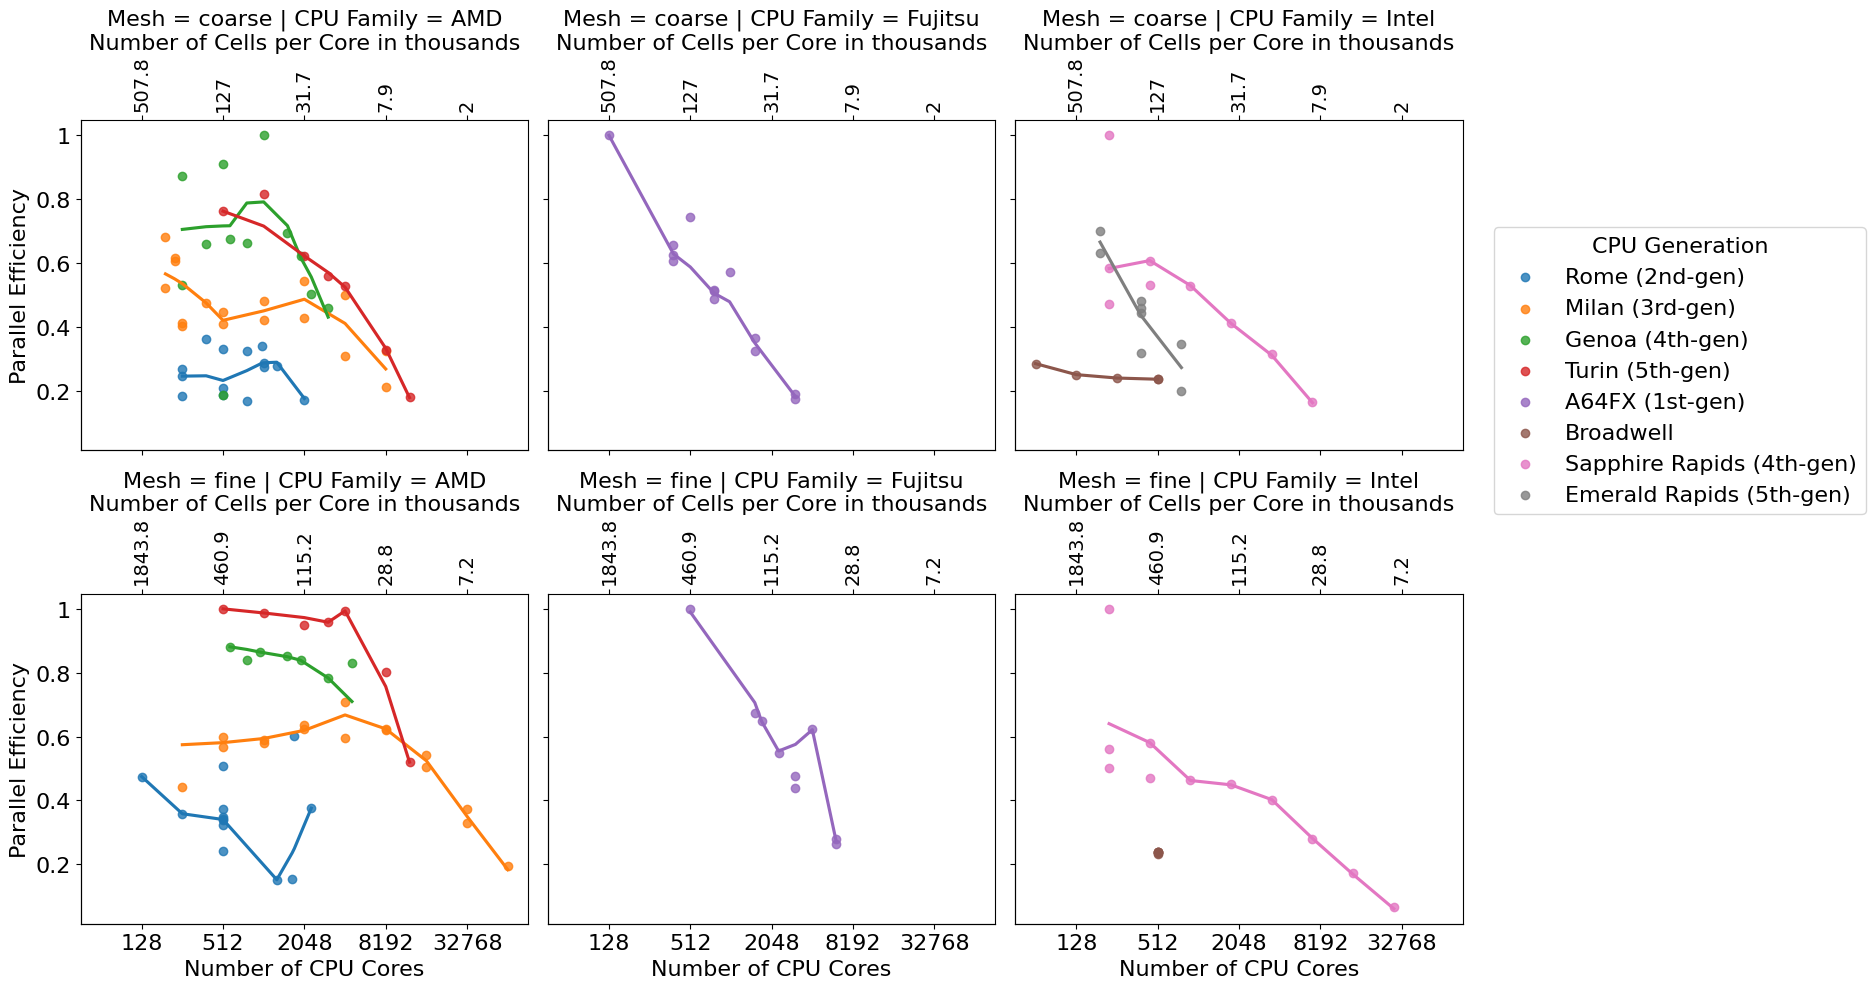

In [17]:
# Use only CPUs with more than one entry per CPU Generation, to ensure that the lowess fit is meaningful
df = df_hardware
df = df.reset_index(drop=True)
df = df[df["Number of Nodes"] > 1]
df = df[df.groupby("CPU Generation")["CPU Generation"].transform(len) > 2]
df = df[df["CPU Family"] != "ARM"]  # Exclude ARM CPUs for this analysis
df = df[df["CPU Family"] != "NVIDIA"]  # Exclude "Other" CPU Generations for this analysis
df = df[df["Mesh"] != "medium"]  # Exclude "Other" CPU Generations for this analysis

# Calculate Total Core Time and find the minimum Total Core Time for each Mesh and CPU Family combination
df["Total Core Time [h]"] = df["Time-To-Solution [h]"] * df["Number of CPU Cores"]
# Exclude medium mesh for the parallel efficiency analysis, as it has only a few submissions and is not representative
for mesh in ["coarse", "fine"]:
    for cpuFamily in df["CPU Family"].unique():
        maxT_val = df["Total Core Time [h]"].where((df["Mesh"] == mesh) & (df["CPU Family"] == cpuFamily)).min()
        maxT_id = df["Total Core Time [h]"].where((df["Mesh"] == mesh) & (df["CPU Family"] == cpuFamily)).idxmin()
        df.loc[(df["Mesh"] == mesh) & (df["CPU Family"] == cpuFamily), "maxT"] = maxT_val

# Calculate Parallel Efficiency
df["Parallel Efficiency"] = df["maxT"] / df["Time-To-Solution [h]"] / df["Number of CPU Cores"]

# Sort the DataFrame by CPU Generation and Mesh to ensure the correct order in the plots
CPUGen_sorting_order = [
    'Rome (2nd-gen)','Milan (3rd-gen)','Genoa (4th-gen)','Turin (5th-gen)',
    'ARMv8.2','ARMv9','A64FX (1st-gen)','Skylake (1st-gen)','Broadwell','Cascade Lake (2nd-gen)',
    'Sapphire Rapids (4th-gen)','Emerald Rapids (5th-gen)',
    'i9']
df["CPUGenIndex"] = df["CPU Generation"].apply(lambda gen: CPUGen_sorting_order.index(gen))
df["MeshIndex"] = df["Mesh"].apply(lambda mesh: ["coarse","medium","fine"].index(mesh))
df = df[df["Mesh"] != "medium"]
# Mesh is categorical; drop the filtered-out level or lmplot draws an empty facet row for it
df["Mesh"] = df["Mesh"].cat.remove_unused_categories()
df = df.sort_values(["MeshIndex", "CPUGenIndex"])

ax = sb.lmplot(
    df,
    x="Number of CPU Cores",
    y="Parallel Efficiency",
    hue="CPU Generation",
    ci=None,
    col="CPU Family",
    row="Mesh",
    lowess=True,
    )

# Adjust axes, labels, and legend
figFontSize = 16
for a in ax.axes.flat:
    a.set_xscale("log", base=2)
    a.xaxis.set_major_formatter(FormatStrFormatter('%.5g'))
    a.yaxis.set_major_formatter(FormatStrFormatter('%.2g'))
    title = a.get_title()
    if "coarse" in title:
        size = size_coarse
    elif "medium" in title:
        size = size_medium
    elif "fine" in title:
        size = size_fine
    else:
        raise ValueError(f"Unexpected title: {title}")
    ax2 = addSecondaryAxisCellsPerCore(a, size, labelFontSize=14)
    fig = a.get_figure()
    for item in ([a.title, a.xaxis.label, a.yaxis.label, ax2.xaxis.label] +
             a.get_xticklabels() + a.get_yticklabels() + ax._legend.texts):
        item.set_fontsize(figFontSize)

ax.tight_layout()
sb.move_legend(ax, "lower right", bbox_to_anchor=(1.08, 0.48), borderaxespad=0,
               frameon=True, ncol=1, fontsize=figFontSize, title_fontsize=figFontSize)
op.save_fig(fig, fig_folder, "efficiency_cores_facetGrid_mesh_CPUFamily", doSaveFig, fig_dpi=200)

# Single-node comparison

## Last-level cache

saving figure to figures_hwtrack/TTS_ETS_facetGrid-singleNode-Last-Level Cache.png


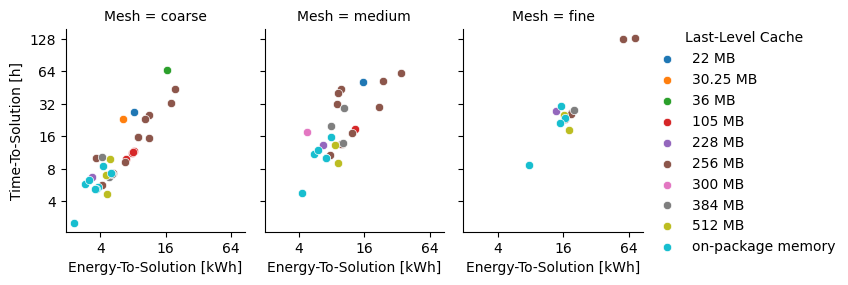

In [18]:
df = df_hardware
df = df[df["Number of Nodes"] == 1].copy()

# Harmonize the Last-Level Cache information, to be able to use it as a hue in the plots
df["Last-Level Cache"] = df["Last-Level Cache"].str.replace(" MB", "MB")
df["Last-Level Cache"] = df["Last-Level Cache"].str.replace("MB", " MB")

# Extract the numeric value of the Last-Level Cache in MB for sorting and plotting
df["Last-Level Cache in MB"] = df["Last-Level Cache"].str.extract(r'(\d+[.\d]*)')
df["Last-Level Cache in MB"] = pd.to_numeric(df["Last-Level Cache in MB"], errors='coerce')
df.sort_values("Last-Level Cache in MB", inplace=True)

g = sb.FacetGrid(
    df,
    col="Mesh",
    hue="Last-Level Cache",
    aspect=0.75,
    sharey=True,
    subplot_kws={"yscale":"log", "xscale":"log"},
    col_order=["coarse","medium","fine"],
    legend_out=True
)

g.map_dataframe(sb.scatterplot, y="Time-To-Solution [h]", x="Energy-To-Solution [kWh]")
g.add_legend(),'ARMv9'
for ax in g.axes.flat:
    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.4g'))
    ax.set_yscale("log", base=2)
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.4g'))

fig = ax.get_figure()
op.save_fig(fig, fig_folder, "TTS_ETS_facetGrid-singleNode-Last-Level Cache", doSaveFig)

## Memory bandwidth

saving figure to figures_hwtrack/TTS_ETS_facetGrid-singleNode-Memory-Bandwidth.png


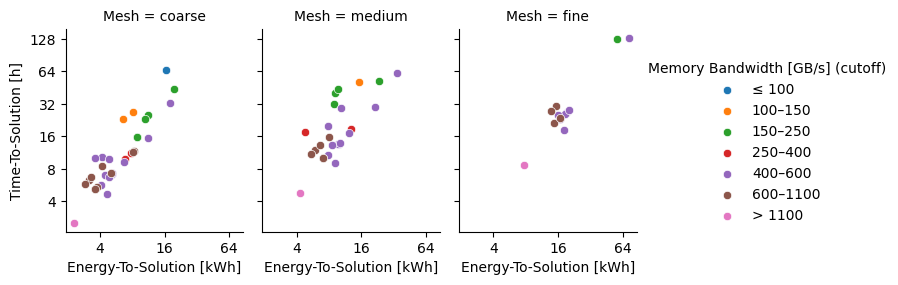

In [19]:
# Same facet grid as the Last-Level Cache plot, but coloured by CPU memory
# bandwidth. The continuous bandwidth is binned into cutoff ranges so the legend
# shows a handful of discrete levels (a "cutoff" per bin) instead of one entry
# per distinct GB/s value.
df = df_hardware
df = df[df["Number of Nodes"] == 1].copy()

bw_edges = [0, 100, 150, 250, 400, 600, 1100, float("inf")]
bw_labels = ["≤ 100", "100–150", "150–250", "250–400",
             "400–600", "600–1100", "> 1100"]
df["Memory Bandwidth [GB/s] (cutoff)"] = pd.cut(
    df["CPU Memory Bandwidth [GB/s]"], bins=bw_edges, labels=bw_labels
)
df.sort_values("CPU Memory Bandwidth [GB/s]", inplace=True)

# Explicit palette: tab10 colours for the bins, but override the last bin's
# washed-out pink with a strong colour so ">1100" (e.g. Vera) stays visible.
bw_palette = dict(zip(bw_labels, sb.color_palette("tab10", len(bw_labels))))
# bw_palette["> 1100"] = "black"

g = sb.FacetGrid(
    df,
    col="Mesh",
    hue="Memory Bandwidth [GB/s] (cutoff)",
    hue_order=bw_labels,
    palette=bw_palette,
    aspect=0.75,
    sharey=True,
    subplot_kws={"yscale":"log", "xscale":"log"},
    col_order=["coarse","medium","fine"],
    legend_out=True
)

g.map_dataframe(sb.scatterplot, y="Time-To-Solution [h]", x="Energy-To-Solution [kWh]")
g.add_legend()
for ax in g.axes.flat:
    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.4g'))
    ax.set_yscale("log", base=2)
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.4g'))

fig = ax.get_figure()
op.save_fig(fig, fig_folder, "TTS_ETS_facetGrid-singleNode-Memory-Bandwidth", doSaveFig)



# FVOPS and cells-per-core

/var/folders/j_/dps_4h917q30x09r6yjydlb80000gn/T/ipykernel_61734/3048513681.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/var/folders/j_/dps_4h917q30x09r6yjydlb80000gn/T/ipykernel_61734/3048513681.py:72: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


saving figure to figures_hwtrack/scaling_count_cpu.png


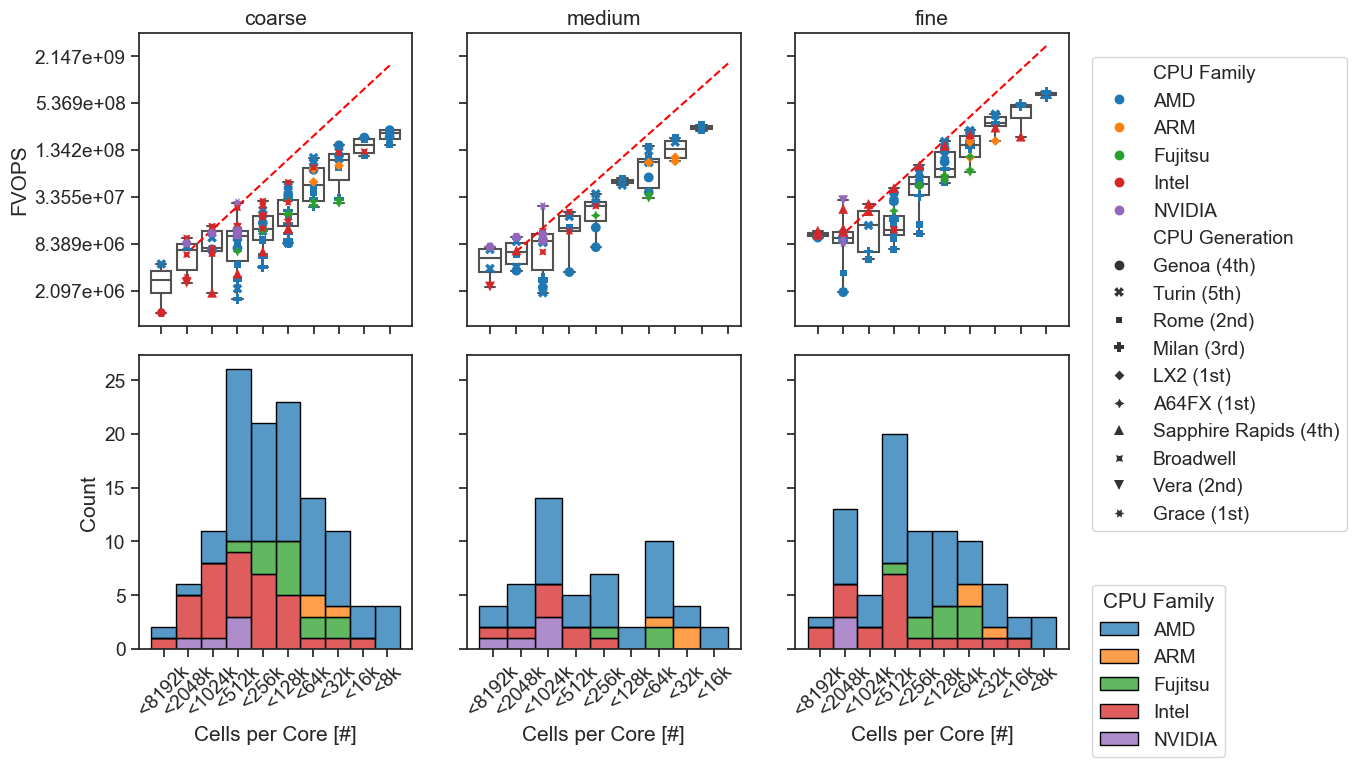

In [20]:
sb.set(style="ticks", font_scale=1.25, palette=sb.color_palette())  # crazy big

fig, axs = plt.subplots(2, 3, figsize=(12, 8), layout="constrained", gridspec_kw={"hspace": 0.1}, sharey="row") # , sharex="col")
df_hardware["FVOPS per Core"] = df_hardware["FVOPS"] / df_hardware["Number of CPU Cores"]
df_hardware["CPU Generation"] = df_hardware["CPU Generation"].apply(lambda x: x.replace("-gen)",")"))

df_hardware["Cells per Core"] = df_hardware["Number of Cells"]/ df_hardware["Number of CPU Cores"]
cellsbin = [1, 8000, 16000, 32000, 64000, 128000, 256000, 512000, 512000*2, 512000*4, 512000*16]
df_hardware["Cells per Core [#]"] = pd.cut(df_hardware["Cells per Core"],
                              bins=cellsbin,
                              labels=["<"+str(int((_/1000)))+"k" for _ in cellsbin[1:]]
                            )

for i,m in enumerate(["coarse", "medium", "fine"]):
    df_filt = df_hardware[df_hardware["Mesh"] == m]
    # get average for mesh and Cells per Core [#] == <8192k
    mean = df_filt[df_filt['Cells per Core [#]'] == "<2048k"]["FVOPS"].mean()

    sb.scatterplot(
        df_filt, x="Cells per Core [#]", y="FVOPS",# color="black",
        #linewidth=0.1,
        size_norm=5, hue="CPU Family", style="CPU Generation", ax=axs[0][i], zorder=20, s=50,   linewidth=0,)
    ax = sb.boxplot(df_filt,
               y="FVOPS",
               x="Cells per Core [#]",
               whis=(0, 100),
               ax = axs[0][i],
               linewidth=1.5
            )

    data = pd.DataFrame.from_dict({"FVOPS":[mean, mean*2048/8],
         "Cells per Core [#]": ["<2048k", "<8k"]}
    )

    sb.lineplot(data, x= "Cells per Core [#]",  y="FVOPS", ax=axs[0][i], color='red', linestyle="--")

    for patch in ax.patches:
        r, g, b, a = patch.get_facecolor()
        patch.set_facecolor((r, g, b, .01))

    ax.set_title(m)
    if i != 2:
        axs[0][i].get_legend().set_visible(False)

    df_filt = df_hardware[df_hardware["Mesh"] == m]
    ax = sb.histplot(
           data=df_filt,
            hue="CPU Family",
            x="Cells per Core [#]",
            multiple="stack",
            stat="count",
            ax=axs[1][i],
            ec="k"
        )
    if i != 2:
        axs[1][i].get_legend().set_visible(False)
    ax.tick_params(axis="x", labelrotation=45)

for i, ax in enumerate(axs[0]):
    ax.set_yscale("log", base=2)
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.4g'))
    ax.tick_params(axis="x", labelbottom=False)  # bin labels are on the bottom row
    ax.set_xlabel("")
    ax.invert_xaxis()
for i, ax in enumerate(axs[1]):
    ax.invert_xaxis()


sb.move_legend(axs[0][2], "upper left", bbox_to_anchor=(1.05, 0.95))
sb.move_legend(axs[1][2], "upper left", bbox_to_anchor=(1.05, 0.25))

fig.tight_layout()
op.save_fig(fig, fig_folder, "scaling_count_cpu", doSaveFig)

# ETS vs. node number

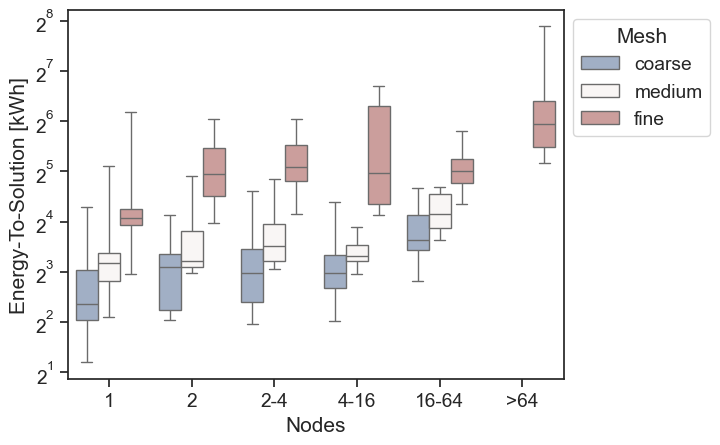

In [21]:
df_hardware["Nodes"] = pd.cut(df_hardware["Number of Nodes"], bins=[0.1,1,2,4,16, 64,64000], labels=["1","2","2-4","4-16", "16-64", ">64"])
df_hardware["Cells per Core"] = df_hardware["Number of Cells"]/df_hardware["Number of CPU Cores"]

fig, ax = plt.subplots()
sb.boxplot(df_hardware, y="Energy-To-Solution [kWh]", x="Nodes", hue="Mesh", palette="vlag", whis=(0, 100), ax=ax)
ax.set_yscale("log", base=2)
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))